![Imgur](https://i.imgur.com/h4PPC71.png)
#**18-modul. Amaliyot. Customer Churn**
# 18.6. Modul boʻyicha yakuniy amaliy vazifa

**Bu vazifa orqali data sayns jarayoni:**

✔️ maʼlumot tayyorlash;

  ✔️ model qurish;

  ✔️ baholash;

  ✔️ natijalarni tahlil qilish
  kabi koʻnikmalarga ega boʻlasiz.

#**Vazifa: bank mijozlarining noroziligini bashorat qilish**

**Vazifa tavsifi**

Sizga bank mijozlari haqida maʼlumotlar toʻplami berilgan. Maqsad – qaysi mijozlar bank xizmatlaridan voz kechishini (churn) oldindan bashorat qilish. Bank bu orqali oʻz mijozlarini ushlab qolish strategiyalarini yaxshilashi mumkin.

**Maʼlumotlar toʻplami**

Kaggle platformasidagi Churn Modelling maʼlumotlar toʻplamidan foydalanamiz. Ushbu toʻplamda 10 000 ta mijozning quyidagi maʼlumotlari mavjud:

- mijoz identifikatori (RowNumber, CustomerId, Surname);
- geografik joylashuvi (Geography);
- jinsi (Gender);
- yoshi (Age);
- kredit balli (CreditScore);
- yillik daromadi (EstimatedSalary);
- bankda qancha vaqtdan beri mijoz ekani (Tenure);
- qancha mahsulotdan foydalanishi (NumOfProducts);
- faoliyati (HasCrCard, IsActiveMember);
- balans (Balance);
- prognoz qilish holati, churn (Exited) – maqsadli oʻzgaruvchi.

**Topshiriqlar**

1. **Maʼlumotlarni tahlil qilish va tozalash:**
   - Maʼlumotlardagi boʻsh qiymatlar va anomaliyalarni aniqlang hamda tozalang.
   - Kategorik oʻzgaruvchilarni raqamli koʻrinishga oʻtkazing (masalan, one-hot encoding yordamida).

2. **Maʼlumotlarni boʻlish:**
   - Maʼlumotlarni training va test toʻplamlariga ajrating (masalan, 80% training, 20% test).

3. **Model qurish:**
   - Quyidagi algoritmlar yordamida modellarni yarating:
     - Logistic Regression
     - Support Vector Machine (SVM)
     - Decision Tree
     - Random Forest
     - XGBoost

4. **Modellarni baholash:**
   - Har bir model uchun quyidagi koʻrsatkichlarni hisoblang:
     - Aniqlik (Accuracy)
     - Toʻgʻrilik (Precision)
     - Recall
     - F1-score

5. **Natijalarni tahlil qilish:**
   - Olingan natijalarni solishtiring va qaysi model eng yaxshi ishlashini aniqlang.
   - Eng yaxshi model asosida bankka mijozlarni ushlab qolish boʻyicha tavsiyalar bering.
---

###*** ESLATMA**. *Ushbu amaliy vazifada siz oʻtmagan mavzulardan ham savollar va vazifalar boʻlishi mumkin! Bu savollarni mustaqil oʻrganishingiz kerak boʻladi. Bunday vazifalar mustaqil izlanish koʻnikmangizni oshirish uchun tayyorlandi!*

In [21]:
import pandas as pd
import numpy as np
import sklearn

url = "https://raw.githubusercontent.com/alishermutalov/praktikum-datasets/refs/heads/praktikum/Churn_Modelling.xls"
df = pd.read_csv(url, index_col='RowNumber')
df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1


## 1. Maʼlumotlarni tahlil qilish va tozalash

### 1.1. Umumiy koʻrinish

In [22]:
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Grafiklar uchun yagona, sokin uslub
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#ecebe7', 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 11,
})
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b5b4ad'

print('Hajmi (qator, ustun):', df.shape)
df.info()

Hajmi (qator, ustun): (10000, 13)
<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 1 to 10000
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 1.1+ MB


In [23]:
print("Boʻsh qiymatlar soni:")
print(df.isna().sum())
print("\nToʻliq takrorlangan qatorlar:", df.duplicated().sum())
print("Takrorlangan CustomerId:", df['CustomerId'].duplicated().sum())

df.describe().T.round(2)

Boʻsh qiymatlar soni:
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Toʻliq takrorlangan qatorlar: 0
Takrorlangan CustomerId: 0


,count,mean,std,min,25%,50%,75%,max
CustomerId,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
CreditScore,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
NumOfProducts,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48
Exited,10000.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00


### 1.2. Anomaliyalarni aniqlash

Ikki xil tekshiruv:
1. **Mantiqiy xatolar** – boʻlishi mumkin boʻlmagan qiymatlar (manfiy balans/maosh, 18 yoshdan kichik mijoz, 300–850 oraligʻidan tashqaridagi kredit balli, binar ustunda 0/1 dan boshqa qiymat).
2. **Statistik chetga chiquvchi qiymatlar** – IQR (Q1 − 1.5·IQR, Q3 + 1.5·IQR) usuli.

In [24]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
bin_cols = ['HasCrCard', 'IsActiveMember', 'Exited']

# 1) Mantiqiy xatolar
invalid = (
    (df[num_cols] < 0).any(axis=1)
    | (df['Age'] < 18)
    | ~df['CreditScore'].between(300, 850)
    | ~df[bin_cols].isin([0, 1]).all(axis=1)
)
print('Mantiqan xato qatorlar soni:', invalid.sum())
print('Geography qiymatlari:', df['Geography'].unique())
print('Gender qiymatlari   :', df['Gender'].unique())

# 2) IQR boʻyicha chetga chiquvchi qiymatlar
def iqr_mask(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

outliers = pd.DataFrame({
    'IQR outlier soni': {c: iqr_mask(df[c]).sum() for c in num_cols},
    'Ulardagi churn ulushi': {c: df.loc[iqr_mask(df[c]), 'Exited'].mean() for c in num_cols},
}).round(3)
outliers

Mantiqan xato qatorlar soni: 0
Geography qiymatlari: ['France' 'Spain' 'Germany']
Gender qiymatlari   : ['Female' 'Male']


,IQR outlier soni,Ulardagi churn ulushi
CreditScore,15,1.000
Age,359,0.203
Tenure,0,NaN
Balance,0,NaN
NumOfProducts,60,1.000
EstimatedSalary,0,NaN


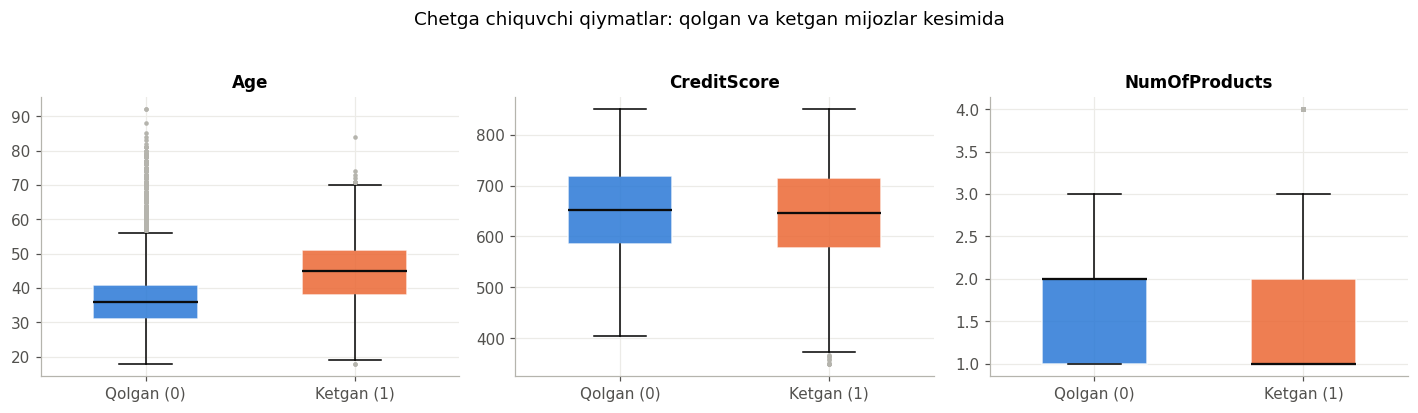

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['Age', 'CreditScore', 'NumOfProducts']):
    parts = [df.loc[df['Exited'] == k, col] for k in (0, 1)]
    bp = ax.boxplot(parts, widths=0.5, patch_artist=True,
                    medianprops=dict(color='#0b0b0b', linewidth=1.5),
                    flierprops=dict(marker='o', markersize=3, markerfacecolor=GRAY, markeredgecolor='none'))
    for patch, c in zip(bp['boxes'], (BLUE, ORANGE)):
        patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor('white')
    ax.set_xticks([1, 2], ['Qolgan (0)', 'Ketgan (1)'])
    ax.set_title(col)
fig.suptitle('Chetga chiquvchi qiymatlar: qolgan va ketgan mijozlar kesimida', y=1.03)
plt.tight_layout(); plt.show()

**Xulosa (tozalash boʻyicha):**
- Boʻsh qiymatlar, takrorlangan qatorlar va mantiqan xato qiymatlar **yoʻq**.
- IQR usuli `Age` (~359 ta, 62+ yosh), `CreditScore` (~15 ta, juda past ball) va `NumOfProducts` (60 ta, 4 ta mahsulot) ustunlarida chetga chiquvchi qiymatlarni topdi. Bular **real mijozlar** – oʻlchov xatosi emas. Bundan tashqari, `CreditScore` va `NumOfProducts` dagi chetga chiquvchi mijozlarning **100% i ketgan** – ular eng muhim signal. Shuning uchun ularni oʻchirmaymiz: aks holda model aynan eng xavfli mijozlarni tanishni oʻrganmay qoladi.
- Daraxtga asoslangan modellar chetga chiquvchi qiymatlarga chidamli; Logistic Regression va SVM uchun esa `StandardScaler` ishlatamiz.
- `CustomerId` va `Surname` – identifikatorlar, bashorat uchun maʼno bermaydi (har bir mijozda noyob) → olib tashlanadi.

Quyidagi tozalash kodi umumiy holatni ham qamrab oladi (agar boʻsh/takror/xato qatorlar boʻlsa, ular olib tashlanadi).

In [26]:
data = (df.loc[~invalid]
          .drop_duplicates()
          .dropna()
          .drop(columns=['CustomerId', 'Surname']))
print('Tozalashdan keyingi hajm:', data.shape)

Tozalashdan keyingi hajm: (10000, 11)


### 1.3. Asosiy bogʻliqliklar (EDA)

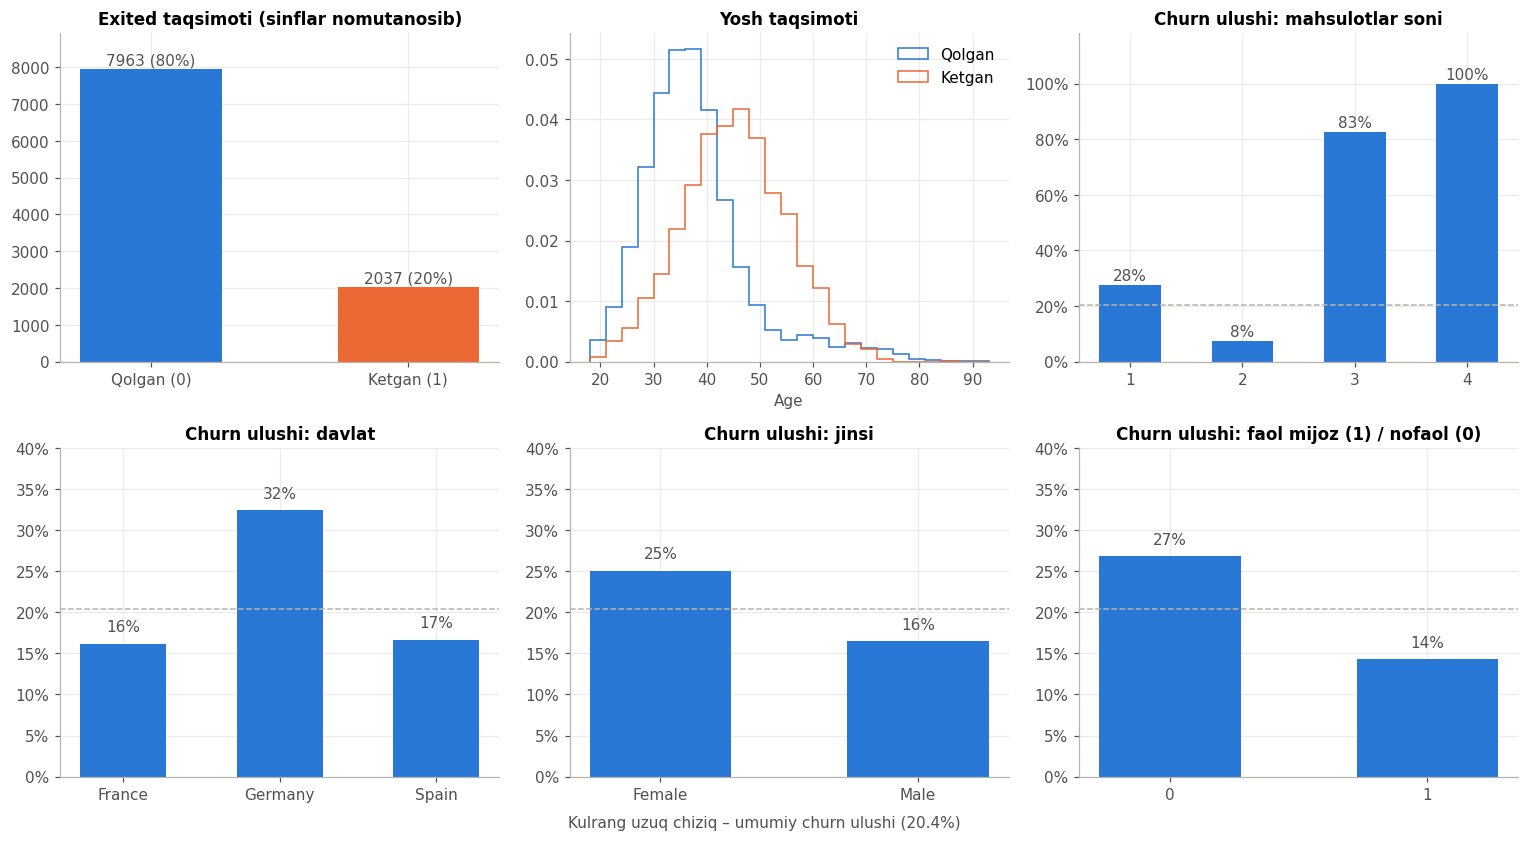

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
overall = df['Exited'].mean()

# Maqsadli oʻzgaruvchi taqsimoti
ax = axes[0, 0]
counts = df['Exited'].value_counts().sort_index()
ax.bar(['Qolgan (0)', 'Ketgan (1)'], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 100, f'{v} ({v / len(df):.0%})', ha='center', color='#52514e')
ax.set_ylim(0, counts.max() * 1.12)
ax.set_title('Exited taqsimoti (sinflar nomutanosib)')

# Yosh taqsimoti
ax = axes[0, 1]
bins = range(18, 94, 3)
ax.hist(df.loc[df['Exited'] == 0, 'Age'], bins=bins, density=True, histtype='step', lw=2, color=BLUE, label='Qolgan')
ax.hist(df.loc[df['Exited'] == 1, 'Age'], bins=bins, density=True, histtype='step', lw=2, color=ORANGE, label='Ketgan')
ax.set_title('Yosh taqsimoti'); ax.set_xlabel('Age'); ax.legend(frameon=False)

# Kategoriyalar boʻyicha churn ulushi
def churn_bar(ax, col, title, order=None):
    rate = df.groupby(col)['Exited'].mean()
    if order is not None:
        rate = rate.reindex(order)
    labels = [str(i) for i in rate.index]
    ax.bar(labels, rate.values, color=BLUE, width=0.55)
    ax.axhline(overall, color=GRAY, ls='--', lw=1)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.015, f'{v:.0%}', ha='center', color='#52514e')
    ax.set_ylim(0, max(rate.max() * 1.18, 0.4))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.set_title(title)

churn_bar(axes[0, 2], 'NumOfProducts', 'Churn ulushi: mahsulotlar soni')
churn_bar(axes[1, 0], 'Geography', 'Churn ulushi: davlat')
churn_bar(axes[1, 1], 'Gender', 'Churn ulushi: jinsi')
churn_bar(axes[1, 2], 'IsActiveMember', 'Churn ulushi: faol mijoz (1) / nofaol (0)')

fig.text(0.5, -0.01, f'Kulrang uzuq chiziq – umumiy churn ulushi ({overall:.1%})', ha='center', color='#52514e')
plt.tight_layout(); plt.show()

### 1.4. Kategorik oʻzgaruvchilarni raqamga oʻtkazish (One-Hot Encoding)

`Geography` (3 ta qiymat) va `Gender` (2 ta qiymat) ustunlari `pd.get_dummies` bilan kodlanadi. `drop_first=True` – multikollinearlikdan (dummy trap) saqlanish uchun bitta ustun tashlanadi (bazaviy kategoriya: France va Female).

In [28]:
data = pd.get_dummies(data, columns=['Geography', 'Gender'], drop_first=True, dtype=int)
print(data.columns.tolist())
data.head()

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
RowNumber,,,,,,,,,,,,
1,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
2,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
3,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
4,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
5,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


## 2. Maʼlumotlarni boʻlish (80% training / 20% test)

`stratify=y` – train va testda churn ulushi (~20%) bir xil saqlanadi.

In [29]:
from sklearn.model_selection import train_test_split

X = data.drop(columns='Exited')
y = data['Exited']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, '| churn ulushi:', round(y_train.mean(), 3))
print('Test :', X_test.shape, ' | churn ulushi:', round(y_test.mean(), 3))

Train: (8000, 11) | churn ulushi: 0.204
Test : (2000, 11)  | churn ulushi: 0.204


## 3. Model qurish

- **Masshtablash:** Logistic Regression va SVM masofa/koeffitsiyentlarga sezgir, shuning uchun ular `Pipeline(StandardScaler → model)` koʻrinishida quriladi (scaler faqat train maʼlumotida oʻrganiladi – *data leakage* yoʻq). Daraxt modellari masshtablashni talab qilmaydi.
- **Sinflar nomutanosibligi:** mijozlarning faqat ~20% i ketgan. Oddiy model “hamma qoladi” deb ham ~80% aniqlikka erishadi, lekin ketayotgan mijozlarni topmaydi. Shuning uchun `class_weight='balanced'` (XGBoost’da `scale_pos_weight`) ishlatamiz va taqqoslash uchun **muvozanatlanmagan (baseline)** variantni ham quramiz.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()   # ≈ 3.9

def build_models(balanced=True):
    cw = 'balanced' if balanced else None
    return {
        'Logistic Regression': make_pipeline(
            StandardScaler(), LogisticRegression(class_weight=cw, max_iter=1000, random_state=42)),
        'SVM': make_pipeline(
            StandardScaler(), SVC(kernel='rbf', C=1.0, class_weight=cw, random_state=42)),
        'Decision Tree': DecisionTreeClassifier(
            max_depth=6, min_samples_leaf=20, class_weight=cw, random_state=42),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, max_depth=10, min_samples_leaf=5,
            class_weight=cw, n_jobs=-1, random_state=42),
        'XGBoost': XGBClassifier(
            n_estimators=300, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=neg_pos_ratio if balanced else 1,
            eval_metric='logloss', random_state=42),
    }

def evaluate(models):
    rows = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        # ROC-AUC uchun: ehtimollik (bor boʻlsa) yoki SVM’ning decision_function qiymati
        score = (model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba')
                 else model.decision_function(X_test))
        rows.append({
            'Model': name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'F1-score': f1_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, score),
        })
    return pd.DataFrame(rows).set_index('Model').round(3)

baseline_results = evaluate(build_models(balanced=False))
models = build_models(balanced=True)
results = evaluate(models)
print('Barcha modellar oʻqitildi.')

Barcha modellar oʻqitildi.


## 4. Modellarni baholash

- **Accuracy** – barcha bashoratlarning necha foizi toʻgʻri.
- **Precision** – “ketadi” deb belgilangan mijozlarning necha foizi haqiqatan ketgan (ortiqcha xarajatdan saqlaydi).
- **Recall** – haqiqatan ketgan mijozlarning necha foizini model topa oldi (bank uchun eng muhimi).
- **F1-score** – Precision va Recall’ning garmonik oʻrtachasi; nomutanosib maʼlumotda asosiy mezon.
- **ROC-AUC** – qoʻshimcha: chegaraga (threshold) bogʻliq boʻlmagan ajratish qobiliyati.

In [17]:
print('Muvozanatlanmagan (baseline) modellar:')
display(baseline_results)

print('\nclass_weight / scale_pos_weight bilan modellar (asosiy natija):')
results.sort_values('F1-score', ascending=False).style.format('{:.3f}').highlight_max(props='background-color: #2a78d6; color: white; font-weight: bold')

Muvozanatlanmagan (baseline) modellar:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.808,0.589,0.187,0.284,0.775
SVM,0.861,0.834,0.396,0.537,0.827
Decision Tree,0.860,0.778,0.440,0.562,0.846
Random Forest,0.869,0.828,0.450,0.583,0.866
XGBoost,0.869,0.780,0.496,0.607,0.866



class_weight / scale_pos_weight bilan modellar (asosiy natija):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.834,0.578,0.686,0.627,0.864
XGBoost,0.804,0.514,0.740,0.606,0.865
SVM,0.787,0.485,0.737,0.585,0.850
Decision Tree,0.762,0.451,0.784,0.572,0.842
Logistic Regression,0.714,0.387,0.700,0.499,0.777


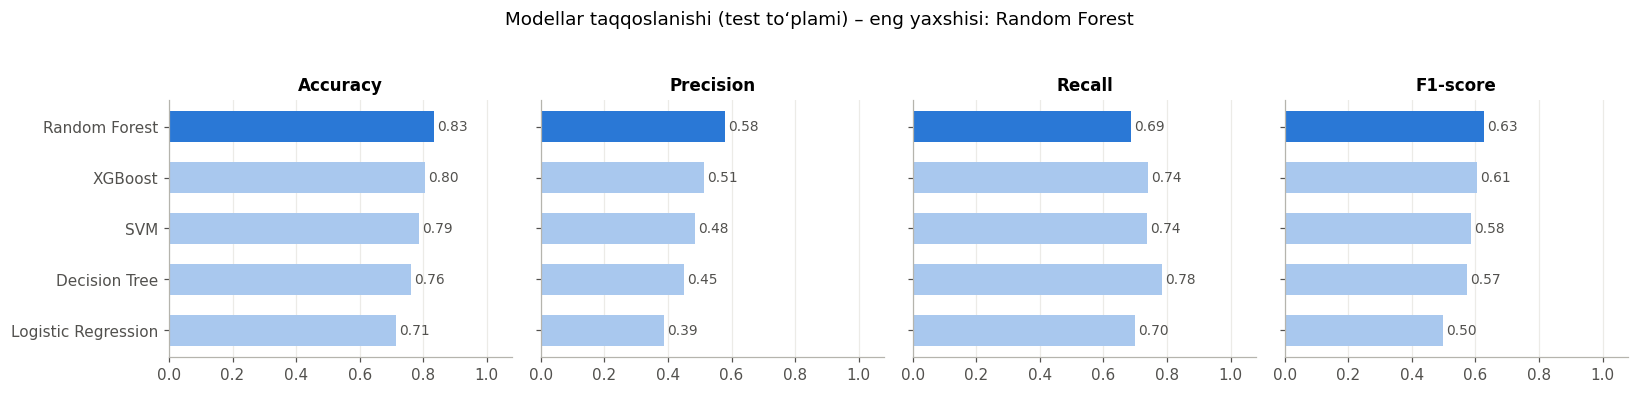

,Recall (baseline),Recall (balanced),F1 (baseline),F1 (balanced)
Model,,,,
Logistic Regression,0.187,0.700,0.284,0.499
SVM,0.396,0.737,0.537,0.585
Decision Tree,0.440,0.784,0.562,0.572
Random Forest,0.450,0.686,0.583,0.627
XGBoost,0.496,0.740,0.607,0.606


In [12]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
best_name = results['F1-score'].idxmax()
order = results.sort_values('F1-score').index

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, m in zip(axes, metrics):
    vals = results.loc[order, m]
    colors = [BLUE if n == best_name else '#a9c8ee' for n in order]
    ax.barh(order, vals, color=colors, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, f'{v:.2f}', va='center', color='#52514e', fontsize=9)
    ax.set_xlim(0, 1.08); ax.set_title(m); ax.grid(axis='y', visible=False)
fig.suptitle(f'Modellar taqqoslanishi (test toʻplami) – eng yaxshisi: {best_name}', y=1.04)
plt.tight_layout(); plt.show()

# Baseline va balanced modellarda Recall farqi
cmp = pd.DataFrame({'Recall (baseline)': baseline_results['Recall'],
                    'Recall (balanced)': results['Recall'],
                    'F1 (baseline)': baseline_results['F1-score'],
                    'F1 (balanced)': results['F1-score']})
cmp

Eng yaxshi model: Random Forest

              precision    recall  f1-score   support

  Qolgan (0)      0.916     0.872     0.893      1593
  Ketgan (1)      0.578     0.686     0.627       407

    accuracy                          0.834      2000
   macro avg      0.747     0.779     0.760      2000
weighted avg      0.847     0.834     0.839      2000



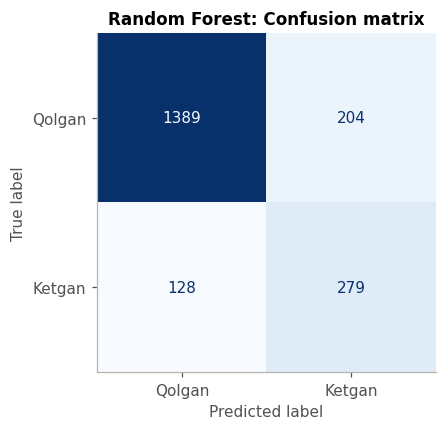

In [13]:
best_model = models[best_name]
y_pred_best = best_model.predict(X_test)

print(f'Eng yaxshi model: {best_name}\n')
print(classification_report(y_test, y_pred_best, target_names=['Qolgan (0)', 'Ketgan (1)'], digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best),
                       display_labels=['Qolgan', 'Ketgan']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.grid(False); ax.set_title(f'{best_name}: Confusion matrix')
plt.show()

## 5. Natijalarni tahlil qilish

### 5.1. Eng muhim belgilar (feature importance)

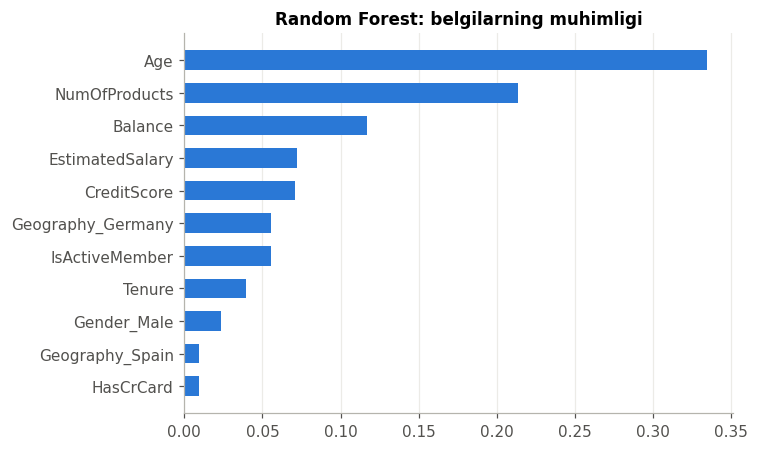

In [14]:
from sklearn.inspection import permutation_importance

est = best_model[-1] if hasattr(best_model, 'steps') else best_model
if hasattr(est, 'feature_importances_'):
    importance = pd.Series(est.feature_importances_, index=X.columns)
else:
    pi = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=5, random_state=42)
    importance = pd.Series(pi.importances_mean, index=X.columns)
importance = importance.sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_title(f'{best_name}: belgilarning muhimligi'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [15]:
# Tavsiyalar uchun: segmentlar boʻyicha churn ulushi
seg = df.assign(
    AgeGroup=pd.cut(df['Age'], [17, 30, 40, 50, 60, 100], labels=['18-30', '31-40', '41-50', '51-60', '60+']),
    BalanceZero=df['Balance'].eq(0).map({True: 'Balans = 0', False: 'Balans > 0'}),
)
segments = pd.concat({
    col: seg.groupby(col, observed=True)['Exited'].agg(churn_ulushi='mean', mijozlar='count')
    for col in ['AgeGroup', 'NumOfProducts', 'IsActiveMember', 'Geography', 'Gender', 'BalanceZero']
})
segments['churn_ulushi'] = segments['churn_ulushi'].map('{:.1%}'.format)
segments

churn_ulushi  mijozlar
AgeGroup       18-30              7.5%      1968
               31-40             12.1%      4451
               41-50             34.0%      2320
               51-60             56.2%       797
               60+               24.8%       464
NumOfProducts  1                 27.7%      5084
               2                  7.6%      4590
               3                 82.7%       266
               4                100.0%        60
IsActiveMember 0                 26.9%      4849
               1                 14.3%      5151
Geography      France            16.2%      5014
               Germany           32.4%      2509
               Spain             16.7%      2477
Gender         Female            25.1%      4543
               Male              16.5%      5457
BalanceZero    Balans = 0        13.8%      3617
               Balans > 0        24.1%      6383

In [16]:
# Amaliy natija: test toʻplamidagi eng yuqori xavfli 10 ta mijoz (ushlab qolish kampaniyasi uchun roʻyxat)
risk_score = (best_model.predict_proba(X_test)[:, 1] if hasattr(best_model, 'predict_proba')
              else best_model.decision_function(X_test))
risk = (df.loc[X_test.index, ['CustomerId', 'Surname', 'Geography', 'Gender', 'Age',
                              'NumOfProducts', 'IsActiveMember', 'Balance', 'Exited']]
          .assign(churn_xavfi=risk_score.round(3))
          .sort_values('churn_xavfi', ascending=False))
risk.head(10)

,CustomerId,Surname,Geography,Gender,Age,NumOfProducts,IsActiveMember,Balance,Exited,churn_xavfi
RowNumber,,,,,,,,,,
6256,15589017,Chiu,Germany,Male,55,3,0,111362.76,1,0.959
3550,15647725,Napolitano,France,Female,61,3,0,62055.17,1,0.953
4733,15653937,McIntyre,Germany,Female,53,1,0,123916.67,1,0.950
777,15712551,Shen,Germany,Female,58,1,0,116922.25,1,0.949
9541,15634551,Williamson,Germany,Male,46,4,0,115248.11,1,0.949
6832,15696989,Chukwueloka,Germany,Female,52,3,0,139493.25,1,0.949
5943,15695339,Lucchesi,Germany,Male,53,1,0,109172.88,1,0.949
2169,15805260,Wood,Germany,Female,56,1,0,143249.67,1,0.942
8674,15707637,Zikoranachukwudimma,France,Female,56,1,0,0.00,1,0.936


### 5.2. Natijalar taqqoslanishi va eng yaxshi model

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest** | **0.834** | **0.578** | 0.686 | **0.627** | 0.864 |
| XGBoost | 0.804 | 0.514 | 0.740 | 0.606 | **0.865** |
| SVM | 0.787 | 0.485 | 0.737 | 0.585 | 0.850 |
| Decision Tree | 0.762 | 0.451 | **0.784** | 0.572 | 0.842 |
| Logistic Regression | 0.714 | 0.387 | 0.700 | 0.499 | 0.777 |

**Asosiy kuzatuvlar:**
1. **“Accuracy tuzogʻi”.** Muvozanatlanmagan (baseline) modellarda accuracy yuqori (0.81–0.87), lekin recall atigi 0.19–0.50 – ular ketayotgan mijozlarning yarmidan koʻpini oʻtkazib yuboradi. `class_weight='balanced'` bilan recall 0.69–0.78 gacha koʻtarildi va F1 ham oshdi. Bank uchun ketayotgan mijozni topa olmaslik qimmatroq, shuning uchun asosiy mezon – **F1 va Recall**.
2. **Eng yaxshi model – Random Forest**: eng yuqori F1 (0.627), Accuracy (0.834) va Precision (0.578), Recall = 0.686, ROC-AUC = 0.864. Testdagi 407 ta ketgan mijozdan **279 tasini** oldindan topadi; “ketadi” deb belgilangan 483 mijozdan 279 tasi haqiqatan ketgan. XGBoost deyarli teng (F1 = 0.606, ROC-AUC = 0.865) va recall’i yuqoriroq (0.740) – ikkalasi ham ansambl modellari boʻlib, nochiziqli bogʻliqliklarni yaxshi ushlaydi. Agar bank uchun iloji boricha koʻproq ketayotgan mijozni topish muhimroq boʻlsa, RF chegarasini (threshold) 0.5 dan pasaytirish yoki XGBoost’ni tanlash mumkin.

   *Izoh: sklearn/xgboost versiyasiga qarab natijalar uchinchi xonada biroz farq qilishi mumkin.*
3. **Logistic Regression eng zaif**, chunki bogʻliqliklar chiziqli emas: masalan, churn 2 ta mahsulotda eng past (8%), 3–4 ta mahsulotda esa eng yuqori (83–100%); yosh boʻyicha ham churn 51–60 yoshda choʻqqiga chiqib, keyin pasayadi.
4. Eng muhim belgilar: **Age, NumOfProducts, Balance**; soʻng EstimatedSalary, CreditScore, Geography_Germany va IsActiveMember. `Tenure`, `Gender_Male`, `Geography_Spain` va `HasCrCard` taʼsiri kichik.

### 5.3. Bankka mijozlarni ushlab qolish boʻyicha tavsiyalar

1. **Erta ogohlantirish tizimi.** Random Forest modeli bilan har oy barcha mijozlarga churn ehtimoli hisoblansin; xavfi yuqori mijozlar roʻyxati (5.1 dagi kabi) ushlab qolish boʻlimiga yuborilsin. Chegara (threshold) xarajatga qarab sozlanadi: taklif arzon boʻlsa – chegarani pasaytirib, koʻproq mijozni qamrab olish mumkin.
2. **40–60 yoshli mijozlar** (eng muhim belgi; 51–60 yoshda churn 56%): shaxsiy menejer, pensiya/jamgʻarma va investitsiya mahsulotlari, depozitlar boʻyicha imtiyozli foiz.
3. **Mahsulotlar soni.** 2 ta mahsulotli mijozlar eng sodiq (churn 8%). 1 ta mahsulotli mijozlarga (28%) ikkinchi mahsulotni taklif qilish (cross-sell: karta, depozit, mobil ilova). 3–4 ta mahsulotli mijozlar (83–100%) – xavf signali: mahsulotlar majburan sotilgan yoki komissiyalar ortiqcha boʻlishi mumkin; ular bilan zudlik bilan bogʻlanib, paketni soddalashtirish kerak.
4. **Nofaol mijozlar** (churn 27% vs faollarda 14%): reaktivatsiya kampaniyalari – keshbek, mobil ilovadagi shaxsiy takliflar, eslatmalar.
5. **Germaniya** (churn 32% – Fransiya va Ispaniyadan 2 baravar koʻp): raqobatchilarning shartlari va xizmat sifatini tahlil qilish, mahalliy tariflarni qayta koʻrib chiqish.
6. **Balansi yuqori mijozlar** (balans > 0 boʻlganlarda churn 24%): bank uchun eng qimmatli mijozlar – premium xizmat, yuqoriroq depozit foizi, ustuvor qoʻllab-quvvatlash.
7. **Ayol mijozlar** (churn 25% vs erkaklarda 16.5%): sabablarini soʻrovnoma orqali aniqlash va moslashtirilgan takliflar ishlab chiqish.
8. **Modelni qoʻllab-quvvatlash.** Modelni har chorakda yangi maʼlumotlar bilan qayta oʻqitish, kampaniyalar samarasini A/B test orqali oʻlchash.